In [1]:
# Only in Colab: work inside the homework folder of Drive (the .py files are there)
import os
import sys
from pathlib import Path
try:
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir("/content/drive/MyDrive/POSGRADOS/HUNGRIA/MASTER/1/FNANCIAL PROCESS /HOMEWORKS/3_HW_LECTURE_5")
except ImportError:
    pass
# the library imports src.enums: put this folder and the repository folder that contains src/ on the path
here = Path.cwd()
root = next((p for p in [here, *here.parents] if (p / 'src' / 'enums.py').exists()), here)
sys.path[:0] = [str(here), str(root)]
print('folder:', here.name, '| repository:', root.name)

folder: 3_HW_LECTURE_5 | repository: QuantCourseBP


**Homework 3: Digital options. Q1: `EuropeanDigitalContract`, `EuropeanDigitalAnalyticPricer` and the unit test**

*Get familiar with digital options and implement EuropeanDigitalContract and EuropeanDigitalAnalyticPricer (fair value and greeks) in the library. Implement unit test for fair value using pytest.* (12 points)

Digital (cash-or-nothing) option: the call pays $1$ if $S_T > K$, the put pays $1$ if $S_T < K$. Prices (Lemma 4 of the report): $C_d = e^{-r\tau}N(d_2)$, $P_d = e^{-r\tau}N(-d_2)$.
Running example (market of the library): `BLUECHIP_BANK`, $S = 130.17$, $\sigma = 0.381$, $r = 0.05$; $K = 130$, $T = 1$.

**Professor's code** (Lecture 5, `solution` folder, copied to this folder: `contract.py`, `market_data.py`, `model.py`, `pricer.py`), unchanged: the library, and the two classes that the new ones follow

In [2]:
from pricer import *        # the library: MarketData, MarketModel, Contract, Pricer, ...


class EuropeanContract(Contract):
    def __init__(self, underlying: Stock, derivative_type: PutCallFwd, long_short: LongShort, strike: float,
                 expiry: float) -> None:
        if derivative_type not in [PutCallFwd.CALL, PutCallFwd.PUT]:
            self.raise_incorrect_derivative_type_error()
        super().__init__(underlying, derivative_type, long_short, strike, expiry)

    def get_timeline(self) -> list[float]:
        return [round(self.expiry, self.timeline_digits)]

    def payoff(self, spot: dict[float, float]) -> float:
        t = self.get_timeline()[0]
        if t not in spot.keys():
            self.raise_missing_spot_error(list(spot.keys()))
        if self.derivative_type == PutCallFwd.CALL:
            return self.direction * max(spot[t] - self.strike, 0)
        elif self.derivative_type == PutCallFwd.PUT:
            return self.direction * max(self.strike - spot[t], 0)
        else:
            self.raise_incorrect_derivative_type_error()


class EuropeanAnalyticPricer(Pricer):
    @staticmethod
    def calc_d1(spot_over_strike: float, vol: float, rate: float, time_to_expiry: float) -> float:
        return 1 / (vol * np.sqrt(time_to_expiry)) * (np.log(spot_over_strike) + (rate + vol**2 / 2) * time_to_expiry)

    @staticmethod
    def calc_d2(spot_over_strike: float, vol: float, rate: float, time_to_expiry: float) -> float:
        d1 = EuropeanAnalyticPricer.calc_d1(spot_over_strike, vol, rate, time_to_expiry)
        return d1 - vol * np.sqrt(time_to_expiry)

    def __init__(self, contract: EuropeanContract, model: MarketModel, params: Params) -> None:
        if not isinstance(contract, EuropeanContract):
            raise TypeError(f'Contract must be of type EuropeanContract but received {type(contract).__name__}')
        super().__init__(contract, model, params)

    def calc_fair_value(self) -> float:
        direction = self.contract.direction
        strike = self.contract.strike
        expiry = self.contract.expiry
        time_to_expiry = expiry - self.valuation_time
        spot = self.model.spot
        vol = self.model.vol
        rate = self.model.risk_free_rate
        df = self.model.calc_df(time_to_expiry)
        d1 = EuropeanAnalyticPricer.calc_d1(spot / strike, vol, rate, time_to_expiry)
        d2 = EuropeanAnalyticPricer.calc_d2(spot / strike, vol, rate, time_to_expiry)
        if self.contract.derivative_type == PutCallFwd.CALL:
            return direction * (spot * norm.cdf(d1) - strike * df * norm.cdf(d2))
        elif self.contract.derivative_type == PutCallFwd.PUT:
            return direction * (strike * df * norm.cdf(-d2) - spot * norm.cdf(-d1))
        else:
            self.contract.raise_incorrect_derivative_type_error()

    def calc_delta(self) -> float:
        greek = 0.0
        spot = self.model.spot
        strike = self.contract.strike
        expiry = self.contract.expiry
        time_to_expiry = expiry - self.valuation_time
        vol = self.model.vol
        rate = self.model.risk_free_rate
        d1 = EuropeanAnalyticPricer.calc_d1(spot / strike, vol, rate, time_to_expiry)
        if self.contract.derivative_type == PutCallFwd.CALL:
            greek = norm.cdf(d1)
        elif self.contract.derivative_type == PutCallFwd.PUT:
            greek = -norm.cdf(-d1)
        else:
            self.contract.raise_incorrect_derivative_type_error()
        return self.contract.direction * greek

    def calc_gamma(self) -> float:
        greek = 0.0
        spot = self.model.spot
        strike = self.contract.strike
        expiry = self.contract.expiry
        time_to_expiry = expiry - self.valuation_time
        vol = self.model.vol
        rate = self.model.risk_free_rate
        d1 = EuropeanAnalyticPricer.calc_d1(spot / strike, vol, rate, time_to_expiry)
        if self.contract.derivative_type in (PutCallFwd.CALL, PutCallFwd.PUT):
            greek = norm.pdf(d1) / (spot * vol * np.sqrt(time_to_expiry))
        else:
            self.contract.raise_incorrect_derivative_type_error()
        return self.contract.direction * greek

    def calc_vega(self) -> float:
        greek = 0.0
        spot = self.model.spot
        strike = self.contract.strike
        expiry = self.contract.expiry
        time_to_expiry = expiry - self.valuation_time
        vol = self.model.vol
        rate = self.model.risk_free_rate
        df = self.model.calc_df(time_to_expiry)
        d2 = EuropeanAnalyticPricer.calc_d2(spot / strike, vol, rate, time_to_expiry)
        if self.contract.derivative_type in (PutCallFwd.CALL, PutCallFwd.PUT):
            greek = strike * df * norm.pdf(d2) * np.sqrt(time_to_expiry)
        else:
            self.contract.raise_incorrect_derivative_type_error()
        return self.contract.direction * greek

    def calc_theta(self) -> float:
        greek = 0.0
        strike = self.contract.strike
        spot = self.model.spot
        expiry = self.contract.expiry
        time_to_expiry = expiry - self.valuation_time
        vol = self.model.vol
        rate = self.model.risk_free_rate
        df = self.model.calc_df(time_to_expiry)
        d1 = EuropeanAnalyticPricer.calc_d1(spot / strike, vol, rate, time_to_expiry)
        d2 = EuropeanAnalyticPricer.calc_d2(spot / strike, vol, rate, time_to_expiry)
        if self.contract.derivative_type == PutCallFwd.CALL:
            greek = -1.0 * ((spot * norm.pdf(d1) * vol) / (2 * np.sqrt(time_to_expiry))
                            + rate * strike * df * norm.cdf(d2))
        elif self.contract.derivative_type == PutCallFwd.PUT:
            greek = -1.0 * ((spot * norm.pdf(d1) * vol) / (2 * np.sqrt(time_to_expiry))
                            - rate * strike * df * norm.cdf(-d2))
        else:
            self.contract.raise_incorrect_derivative_type_error()
        return self.contract.direction * greek

    def calc_rho(self) -> float:
        greek = 0.0
        strike = self.contract.strike
        expiry = self.contract.expiry
        time_to_expiry = expiry - self.valuation_time
        spot = self.model.spot
        vol = self.model.vol
        rate = self.model.risk_free_rate
        df = self.model.calc_df(time_to_expiry)
        d2 = EuropeanAnalyticPricer.calc_d2(spot / strike, vol, rate, time_to_expiry)
        if self.contract.derivative_type == PutCallFwd.CALL:
            greek = strike * time_to_expiry * df * norm.cdf(d2)
        elif self.contract.derivative_type == PutCallFwd.PUT:
            greek = -strike * time_to_expiry * df * norm.cdf(-d2)
        else:
            self.contract.raise_incorrect_derivative_type_error()
        return self.contract.direction * greek

**Test of the professor's code**: the long call of the running example, and put-call parity LC + SP = LF (Lecture 5)

In [3]:
# test of the professor's code: BLUECHIP_BANK, K = 130, T = 1
model = MarketModel(Stock.BLUECHIP_BANK)
lc = EuropeanAnalyticPricer(EuropeanContract(Stock.BLUECHIP_BANK, PutCallFwd.CALL, LongShort.LONG, 130.0, 1.0), model, Params())
sp = EuropeanAnalyticPricer(EuropeanContract(Stock.BLUECHIP_BANK, PutCallFwd.PUT, LongShort.SHORT, 130.0, 1.0), model, Params())
lf = ForwardAnalyticPricer(ForwardContract(Stock.BLUECHIP_BANK, LongShort.LONG, 130.0, 1.0), model, Params())
print(f"long call = {lc.calc_fair_value():.4f},  LC + SP = {lc.calc_fair_value() + sp.calc_fair_value():.4f},  LF = {lf.calc_fair_value():.4f}")

long call = 22.6012,  LC + SP = 6.5102,  LF = 6.5102


**Blocks at the start** (library copied from the `solution` folder). Bold with NEW: created by the code above; faded: still to come.

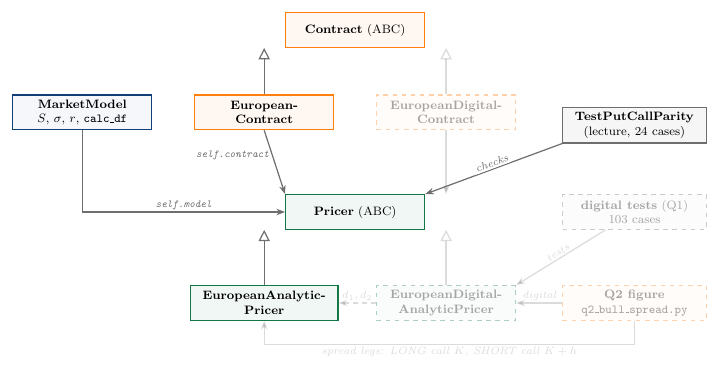

**NEW VERSION of `EuropeanContract`: `EuropeanDigitalContract`** (NEW CODE, file `contract.py`)

- change # 1: new name; the parent is `Contract`, not `EuropeanContract` (otherwise `EuropeanAnalyticPricer` would accept a digital and price it as a vanilla);
- change # 2: the type is stored before the error is raised (in the lecture code this line is missing and a forward gives `AttributeError`);
- changes # 3, # 4: the payoff is `direction` $\cdot\,\mathbf{1}\{S_T>K\}$ (call) or `direction` $\cdot\,\mathbf{1}\{S_T<K\}$ (put).

In [4]:
# =====================================================================================================
# Homework 3, Q1 (NEW CODE): NEW VERSION of EuropeanContract for a digital (cash-or-nothing) option.
# The payoff is 1 if the option ends in the money, else 0 (Definition 1 of the report).
# =====================================================================================================
# change # 1
#Delete.class EuropeanContract(Contract):
# replace by
class EuropeanDigitalContract(Contract):    # parent Contract, not EuropeanContract: the vanilla pricer must reject it
# end change # 1
    def __init__(self, underlying: Stock, derivative_type: PutCallFwd, long_short: LongShort, strike: float,
                 expiry: float) -> None:
        if derivative_type not in [PutCallFwd.CALL, PutCallFwd.PUT]:
            # change # 2: store the type first, so that the error message can be built (lecture code: AttributeError)
            self.derivative_type = derivative_type
            # end change # 2
            self.raise_incorrect_derivative_type_error()
        super().__init__(underlying, derivative_type, long_short, strike, expiry)

    def get_timeline(self) -> list[float]:
        return [round(self.expiry, self.timeline_digits)]

    def payoff(self, spot: dict[float, float]) -> float:
        t = self.get_timeline()[0]
        if t not in spot.keys():
            self.raise_missing_spot_error(list(spot.keys()))
        if self.derivative_type == PutCallFwd.CALL:
            # change # 3
            #Delete.    return self.direction * max(spot[t] - self.strike, 0)
            # replace by
            return self.direction if spot[t] > self.strike else 0.0     # direction * 1{S_T > K}
            # end change # 3
        elif self.derivative_type == PutCallFwd.PUT:
            # change # 4
            #Delete.    return self.direction * max(self.strike - spot[t], 0)
            # replace by
            return self.direction if spot[t] < self.strike else 0.0     # direction * 1{S_T < K}
            # end change # 4
        else:
            self.raise_incorrect_derivative_type_error()

**Test of the NEW VERSION**: payoffs, and the type checks

In [5]:
# test of EuropeanDigitalContract: K = 130, T = 1
long_call = EuropeanDigitalContract(Stock.BLUECHIP_BANK, PutCallFwd.CALL, LongShort.LONG, 130.0, 1.0)
short_put = EuropeanDigitalContract(Stock.BLUECHIP_BANK, PutCallFwd.PUT, LongShort.SHORT, 130.0, 1.0)
for s_T in [129.0, 131.0]:
    print(f"S_T = {s_T}: long digital call pays {long_call.payoff({1.0: s_T})}, short digital put pays {short_put.payoff({1.0: s_T})}")
try:
    EuropeanDigitalContract(Stock.BLUECHIP_BANK, PutCallFwd.FWD, LongShort.LONG, 130.0, 1.0)
except ValueError as e:
    print("ValueError:", e)
try:
    EuropeanAnalyticPricer(long_call, MarketModel(Stock.BLUECHIP_BANK), Params())
except TypeError as e:
    print("TypeError:", e)

S_T = 129.0: long digital call pays 0.0, short digital put pays -1.0
S_T = 131.0: long digital call pays 1.0, short digital put pays 0.0
ValueError: Derivative type of EuropeanDigitalContract must be one of CALL, PUT, but received PutCallFwd.FWD
TypeError: Contract must be of type EuropeanContract but received EuropeanDigitalContract


**Blocks after the NEW VERSION of the contract**: `EuropeanDigitalContract` (NEW).

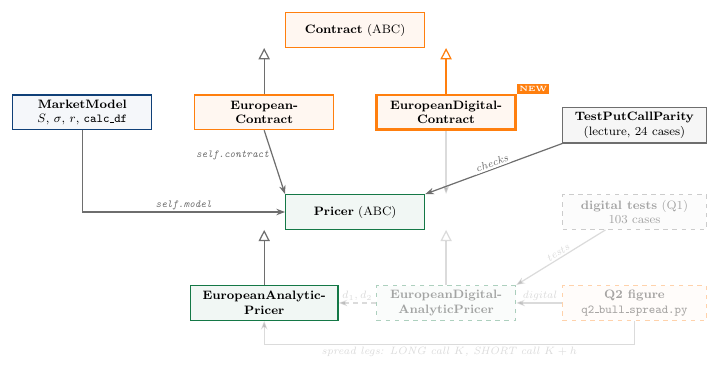

**NEW VERSION of `EuropeanAnalyticPricer`: `EuropeanDigitalAnalyticPricer`** (NEW CODE, file `pricer.py`)

With $\tau = T - t$, $DF = e^{-r\tau}$ and $d_1, d_2$ of the lecture (static methods of `EuropeanAnalyticPricer`, reused):

| | digital call | digital put ($= DF -$ call) |
|---|---|---|
| fair value | $DF\,N(d_2)$ | $DF\,N(-d_2)$ |
| delta | $DF\,\varphi(d_2)/(S\sigma\sqrt\tau)$ | $-$ call |
| gamma | $-DF\,\varphi(d_2)\,d_1/(S^2\sigma^2\tau)$ | $-$ call |
| vega | $-DF\,\varphi(d_2)\,d_1/\sigma$ | $-$ call |
| theta | $r\,DF\,N(d_2) + DF\,\varphi(d_2)\,\big(d_1/(2\tau) - r/(\sigma\sqrt\tau)\big)$ | $r\,DF -$ call |
| rho | $-\tau\,DF\,N(d_2) + DF\,\varphi(d_2)\sqrt\tau/\sigma$ | $-\tau\,DF -$ call |

Each value is multiplied by `direction` (LONG $+1$, SHORT $-1$), as in the lecture.

In [6]:
# =====================================================================================================
# Homework 3, Q1 (NEW CODE): NEW VERSION of EuropeanAnalyticPricer for EuropeanDigitalContract.
# Fair value (Lemma 4 of the report):  call  DF * N(d2),   put  DF * N(-d2) = DF - call   (DF = e^{-r tau})
# Greeks (Lemma 5): derivatives of DF * N(d2); the put follows from put = DF - call.
# d1, d2 are the static methods of EuropeanAnalyticPricer (reused, not copied).
# =====================================================================================================
# change # 1
#Delete.class EuropeanAnalyticPricer(Pricer):
# replace by
class EuropeanDigitalAnalyticPricer(Pricer):
# end change # 1
    # change # 2
    #Delete.def __init__(self, contract: EuropeanContract, model: MarketModel, params: Params) -> None:
    #Delete.    if not isinstance(contract, EuropeanContract):
    #Delete.        raise TypeError(f'Contract must be of type EuropeanContract but received {type(contract).__name__}')
    # replace by
    def __init__(self, contract: EuropeanDigitalContract, model: MarketModel, params: Params) -> None:
        if not isinstance(contract, EuropeanDigitalContract):
            raise TypeError(f'Contract must be of type EuropeanDigitalContract but received {type(contract).__name__}')
    # end change # 2
        super().__init__(contract, model, params)

    def calc_fair_value(self) -> float:
        direction = self.contract.direction
        strike = self.contract.strike
        expiry = self.contract.expiry
        time_to_expiry = expiry - self.valuation_time
        spot = self.model.spot
        vol = self.model.vol
        rate = self.model.risk_free_rate
        df = self.model.calc_df(time_to_expiry)
        # change # 3
        #Delete.d1 = EuropeanAnalyticPricer.calc_d1(spot / strike, vol, rate, time_to_expiry)
        d2 = EuropeanAnalyticPricer.calc_d2(spot / strike, vol, rate, time_to_expiry)
        #Delete.if self.contract.derivative_type == PutCallFwd.CALL:
        #Delete.    return direction * (spot * norm.cdf(d1) - strike * df * norm.cdf(d2))
        #Delete.elif self.contract.derivative_type == PutCallFwd.PUT:
        #Delete.    return direction * (strike * df * norm.cdf(-d2) - spot * norm.cdf(-d1))
        # replace by
        if self.contract.derivative_type == PutCallFwd.CALL:
            return direction * df * norm.cdf(d2)
        elif self.contract.derivative_type == PutCallFwd.PUT:
            return direction * df * norm.cdf(-d2)
        # end change # 3
        else:
            self.contract.raise_incorrect_derivative_type_error()

    def calc_delta(self) -> float:
        greek = 0.0
        spot = self.model.spot
        strike = self.contract.strike
        expiry = self.contract.expiry
        time_to_expiry = expiry - self.valuation_time
        vol = self.model.vol
        rate = self.model.risk_free_rate
        # change # 4
        #Delete.d1 = EuropeanAnalyticPricer.calc_d1(spot / strike, vol, rate, time_to_expiry)
        #Delete.if self.contract.derivative_type == PutCallFwd.CALL:
        #Delete.    greek = norm.cdf(d1)
        #Delete.elif self.contract.derivative_type == PutCallFwd.PUT:
        #Delete.    greek = -norm.cdf(-d1)
        # replace by
        df = self.model.calc_df(time_to_expiry)
        d2 = EuropeanAnalyticPricer.calc_d2(spot / strike, vol, rate, time_to_expiry)
        call_greek = df * norm.pdf(d2) / (spot * vol * np.sqrt(time_to_expiry))
        if self.contract.derivative_type == PutCallFwd.CALL:
            greek = call_greek
        elif self.contract.derivative_type == PutCallFwd.PUT:
            greek = -call_greek                                  # put = DF - call
        # end change # 4
        else:
            self.contract.raise_incorrect_derivative_type_error()
        return self.contract.direction * greek

    def calc_gamma(self) -> float:
        greek = 0.0
        spot = self.model.spot
        strike = self.contract.strike
        expiry = self.contract.expiry
        time_to_expiry = expiry - self.valuation_time
        vol = self.model.vol
        rate = self.model.risk_free_rate
        # change # 5
        #Delete.d1 = EuropeanAnalyticPricer.calc_d1(spot / strike, vol, rate, time_to_expiry)
        #Delete.if self.contract.derivative_type in (PutCallFwd.CALL, PutCallFwd.PUT):
        #Delete.    greek = norm.pdf(d1) / (spot * vol * np.sqrt(time_to_expiry))
        # replace by
        df = self.model.calc_df(time_to_expiry)
        d1 = EuropeanAnalyticPricer.calc_d1(spot / strike, vol, rate, time_to_expiry)
        d2 = EuropeanAnalyticPricer.calc_d2(spot / strike, vol, rate, time_to_expiry)
        call_greek = -df * norm.pdf(d2) * d1 / (spot**2 * vol**2 * time_to_expiry)
        if self.contract.derivative_type == PutCallFwd.CALL:
            greek = call_greek
        elif self.contract.derivative_type == PutCallFwd.PUT:
            greek = -call_greek
        # end change # 5
        else:
            self.contract.raise_incorrect_derivative_type_error()
        return self.contract.direction * greek

    def calc_vega(self) -> float:
        greek = 0.0
        spot = self.model.spot
        strike = self.contract.strike
        expiry = self.contract.expiry
        time_to_expiry = expiry - self.valuation_time
        vol = self.model.vol
        rate = self.model.risk_free_rate
        df = self.model.calc_df(time_to_expiry)
        # change # 6
        #Delete.d2 = EuropeanAnalyticPricer.calc_d2(spot / strike, vol, rate, time_to_expiry)
        #Delete.if self.contract.derivative_type in (PutCallFwd.CALL, PutCallFwd.PUT):
        #Delete.    greek = strike * df * norm.pdf(d2) * np.sqrt(time_to_expiry)
        # replace by
        d1 = EuropeanAnalyticPricer.calc_d1(spot / strike, vol, rate, time_to_expiry)
        d2 = EuropeanAnalyticPricer.calc_d2(spot / strike, vol, rate, time_to_expiry)
        call_greek = -df * norm.pdf(d2) * d1 / vol
        if self.contract.derivative_type == PutCallFwd.CALL:
            greek = call_greek
        elif self.contract.derivative_type == PutCallFwd.PUT:
            greek = -call_greek
        # end change # 6
        else:
            self.contract.raise_incorrect_derivative_type_error()
        return self.contract.direction * greek

    def calc_theta(self) -> float:
        greek = 0.0
        strike = self.contract.strike
        spot = self.model.spot
        expiry = self.contract.expiry
        time_to_expiry = expiry - self.valuation_time
        vol = self.model.vol
        rate = self.model.risk_free_rate
        df = self.model.calc_df(time_to_expiry)
        d1 = EuropeanAnalyticPricer.calc_d1(spot / strike, vol, rate, time_to_expiry)
        d2 = EuropeanAnalyticPricer.calc_d2(spot / strike, vol, rate, time_to_expiry)
        # change # 7
        #Delete.if self.contract.derivative_type == PutCallFwd.CALL:
        #Delete.    greek = -1.0 * ((spot * norm.pdf(d1) * vol) / (2 * np.sqrt(time_to_expiry))
        #Delete.                    + rate * strike * df * norm.cdf(d2))
        #Delete.elif self.contract.derivative_type == PutCallFwd.PUT:
        #Delete.    greek = -1.0 * ((spot * norm.pdf(d1) * vol) / (2 * np.sqrt(time_to_expiry))
        #Delete.                    - rate * strike * df * norm.cdf(-d2))
        # replace by
        call_greek = (rate * df * norm.cdf(d2)
                      + df * norm.pdf(d2) * (d1 / (2 * time_to_expiry) - rate / (vol * np.sqrt(time_to_expiry))))
        if self.contract.derivative_type == PutCallFwd.CALL:
            greek = call_greek
        elif self.contract.derivative_type == PutCallFwd.PUT:
            greek = rate * df - call_greek                       # theta of DF = e^{-r(T-t)} is r * DF
        # end change # 7
        else:
            self.contract.raise_incorrect_derivative_type_error()
        return self.contract.direction * greek

    def calc_rho(self) -> float:
        greek = 0.0
        strike = self.contract.strike
        expiry = self.contract.expiry
        time_to_expiry = expiry - self.valuation_time
        spot = self.model.spot
        vol = self.model.vol
        rate = self.model.risk_free_rate
        df = self.model.calc_df(time_to_expiry)
        d2 = EuropeanAnalyticPricer.calc_d2(spot / strike, vol, rate, time_to_expiry)
        # change # 8
        #Delete.if self.contract.derivative_type == PutCallFwd.CALL:
        #Delete.    greek = strike * time_to_expiry * df * norm.cdf(d2)
        #Delete.elif self.contract.derivative_type == PutCallFwd.PUT:
        #Delete.    greek = -strike * time_to_expiry * df * norm.cdf(-d2)
        # replace by
        call_greek = -time_to_expiry * df * norm.cdf(d2) + df * norm.pdf(d2) * np.sqrt(time_to_expiry) / vol
        if self.contract.derivative_type == PutCallFwd.CALL:
            greek = call_greek
        elif self.contract.derivative_type == PutCallFwd.PUT:
            greek = -time_to_expiry * df - call_greek            # rho of DF = e^{-r tau} is -tau * DF
        # end change # 8
        else:
            self.contract.raise_incorrect_derivative_type_error()
        return self.contract.direction * greek

**Test of the NEW VERSION** (file `q1_digital_demo.py`): fair values and parity, the bull-spread bounds of Lemma 4 with the lecture's vanilla pricer, and the Greeks against bump and revaluation

In [7]:
# running example: the market of the library
model = MarketModel(Stock.BLUECHIP_BANK)
strike, expiry = 130.0, 1.0
print(f'market: S = {model.spot}, vol = {model.vol}, r = {model.risk_free_rate};  K = {strike}, T = {expiry}')

# 1. payoffs of the new contract (Definition 1)
long_call = EuropeanDigitalContract(Stock.BLUECHIP_BANK, PutCallFwd.CALL, LongShort.LONG, strike, expiry)
short_put = EuropeanDigitalContract(Stock.BLUECHIP_BANK, PutCallFwd.PUT, LongShort.SHORT, strike, expiry)
for s_T in [129.0, 131.0]:
    print(f'S_T = {s_T}: long digital call pays {long_call.payoff({expiry: s_T})}, '
          f'short digital put pays {short_put.payoff({expiry: s_T})}')

# 2. fair values (Lemma 4) and parity C_d + P_d = DF
pricers = {cp: EuropeanDigitalAnalyticPricer(
               EuropeanDigitalContract(Stock.BLUECHIP_BANK, cp, LongShort.LONG, strike, expiry), model, Params())
           for cp in (PutCallFwd.CALL, PutCallFwd.PUT)}
call, put = (pricers[cp].calc_fair_value() for cp in (PutCallFwd.CALL, PutCallFwd.PUT))
df = model.calc_df(expiry)
d2 = EuropeanAnalyticPricer.calc_d2(model.spot / strike, model.vol, model.risk_free_rate, expiry)
print(f'd2 = {d2:.6f}, DF = {df:.6f}')
print(f'digital call = {call:.6f}, digital put = {put:.6f}, call + put = {call + put:.6f} (DF = {df:.6f})')


# 3. bull spreads with the lecture's vanilla pricer (proof of Lemma 4)
def vanilla_call(k: float) -> float:
    contract = EuropeanContract(Stock.BLUECHIP_BANK, PutCallFwd.CALL, LongShort.LONG, k, expiry)
    return EuropeanAnalyticPricer(contract, model, Params()).calc_fair_value()


for h in [10.0, 1.0, 0.1, 0.01]:
    lower = (vanilla_call(strike) - vanilla_call(strike + h)) / h
    upper = (vanilla_call(strike - h) - vanilla_call(strike)) / h
    print(f'h = {h:5.2f}: {lower:.6f} <= C_d = {call:.6f} <= {upper:.6f}   {lower <= call <= upper}')

# 4. Greeks (Lemma 5) against bump and revaluation
print(f"{'':6s}{'call':>11s}{'put':>11s}{'call bump':>11s}")
pc = pricers[PutCallFwd.CALL]
hs, h = 0.01, 1e-4


def bumped(attribute: str, step: float) -> float:
    owner = pc if attribute == 'valuation_time' else model
    base = getattr(owner, attribute)
    setattr(owner, attribute, base + step)
    value = pc.calc_fair_value()
    setattr(owner, attribute, base)
    return value


bumps = {'delta': (bumped('spot', hs) - bumped('spot', -hs)) / (2 * hs),
         'gamma': (bumped('spot', hs) - 2 * call + bumped('spot', -hs)) / hs**2,
         'vega': (bumped('vol', h) - bumped('vol', -h)) / (2 * h),
         'theta': (bumped('valuation_time', h) - bumped('valuation_time', -h)) / (2 * h),
         'rho': (bumped('risk_free_rate', h) - bumped('risk_free_rate', -h)) / (2 * h)}
for g, b in bumps.items():
    gc = getattr(pricers[PutCallFwd.CALL], f'calc_{g}')()
    gp = getattr(pricers[PutCallFwd.PUT], f'calc_{g}')()
    print(f'{g:6s}{gc:11.6f}{gp:11.6f}{b:11.6f}')

market: S = 130.17, vol = 0.381, r = 0.05;  K = 130.0, T = 1.0
S_T = 129.0: long digital call pays 0.0, short digital put pays -1.0
S_T = 131.0: long digital call pays 1.0, short digital put pays 0.0
d2 = -0.055836, DF = 0.951229
digital call = 0.454437, digital put = 0.496793, call + put = 0.951229 (DF = 0.951229)
h = 10.00: 0.417385 <= C_d = 0.454437 <= 0.493716   True
h =  1.00: 0.450623 <= C_d = 0.454437 <= 0.458273   True
h =  0.10: 0.454054 <= C_d = 0.454437 <= 0.454819   True
h =  0.01: 0.454398 <= C_d = 0.454437 <= 0.454475   True
             call        put  call bump
delta    0.007640  -0.007640   0.007640
gamma   -0.000050   0.000050  -0.000050
vega    -0.323367   0.323367  -0.323367
theta    0.034599   0.012962   0.034599
rho      0.540037  -1.491267   0.540037


**Blocks after the NEW VERSION of the pricer**: `EuropeanDigitalAnalyticPricer` (NEW); it reuses the static `calc_d1`, `calc_d2`.

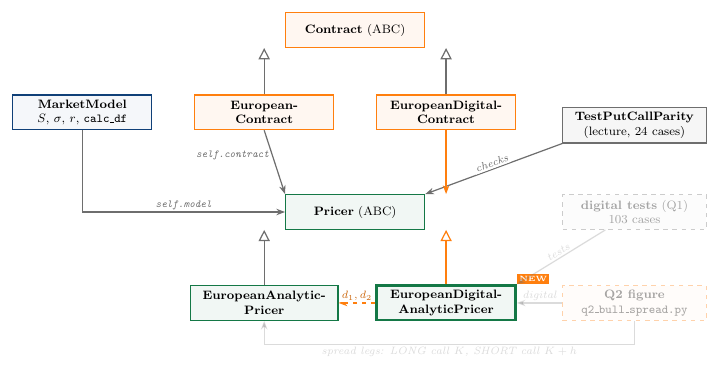

**Unit tests** (NEW CODE, file `test_pricer.py`, after the professor's `TestPutCallParity`)

- `TestDigitalFairValue` (2 stocks $\times$ 3 values of $K/S$ $\times$ 4 expiries $= 24$ cases, 4 tests each): parity $C_d + P_d = DF$; bull-spread bounds; narrow bull spread $=$ digital; short $= -$ long;
- `test_digital_value_by_hand`: $C_d = 0.454437$, $P_d = 0.496793$;
- `test_digital_payoff`, `test_digital_type_checks`, `test_digital_greeks_bump` (4 cases).

In [8]:
import pytest      # as at the top of test_pricer.py


# =====================================================================================================
# Homework 3, Q1 (NEW CODE): unit tests of the digital option.
# Fair value (asked in the assignment) + payoff, type checks and Greeks.
# =====================================================================================================
def digital_pricer(model: MarketModel, call_put: PutCallFwd, long_short: LongShort, strike: float,
                   expiry: float) -> EuropeanDigitalAnalyticPricer:
    contract = EuropeanDigitalContract(model.underlying, call_put, long_short, strike, expiry)
    return EuropeanDigitalAnalyticPricer(contract, model, Params())


def call_price(model: MarketModel, strike: float, expiry: float) -> float:
    """Long vanilla call of the lecture (EuropeanAnalyticPricer)."""
    contract = EuropeanContract(model.underlying, PutCallFwd.CALL, LongShort.LONG, strike, expiry)
    return EuropeanAnalyticPricer(contract, model, Params()).calc_fair_value()


@pytest.mark.parametrize('underlying', [Stock.BLUECHIP_BANK, Stock.TIPTOP_SOLUTIONS])
@pytest.mark.parametrize('strike_over_spot', np.arange(0.5, 2.0, 0.5))
@pytest.mark.parametrize('expiry', np.arange(0.5, 2.5, 0.5))
class TestDigitalFairValue:
    def test_digital_parity(self, underlying, strike_over_spot, expiry):
        # long digital call + long digital put pay 1 at T, worth DF = e^{-rT} today (Lemma 4)
        model = MarketModel(underlying)
        strike = strike_over_spot * model.spot
        call = digital_pricer(model, PutCallFwd.CALL, LongShort.LONG, strike, expiry).calc_fair_value()
        put = digital_pricer(model, PutCallFwd.PUT, LongShort.LONG, strike, expiry).calc_fair_value()
        assert call + put == pytest.approx(model.calc_df(expiry), abs=1e-12)

    def test_bull_spread_bounds(self, underlying, strike_over_spot, expiry):
        # (c(K) - c(K+h))/h <= C_d <= (c(K-h) - c(K))/h for every h > 0 (proof of Lemma 4); h = 1% of K
        model = MarketModel(underlying)
        strike = strike_over_spot * model.spot
        h = 0.01 * strike
        digital = digital_pricer(model, PutCallFwd.CALL, LongShort.LONG, strike, expiry).calc_fair_value()
        lower = (call_price(model, strike, expiry) - call_price(model, strike + h, expiry)) / h
        upper = (call_price(model, strike - h, expiry) - call_price(model, strike, expiry)) / h
        assert lower <= digital <= upper

    def test_bull_spread_limit(self, underlying, strike_over_spot, expiry):
        # a narrow scaled bull spread (width h = 0.01% of K) has the price of the digital call (Lemma 4)
        model = MarketModel(underlying)
        strike = strike_over_spot * model.spot
        h = 1e-4 * strike
        digital = digital_pricer(model, PutCallFwd.CALL, LongShort.LONG, strike, expiry).calc_fair_value()
        spread = (call_price(model, strike - h / 2, expiry) - call_price(model, strike + h / 2, expiry)) / h
        assert spread == pytest.approx(digital, abs=1e-6)

    def test_short_is_minus_long(self, underlying, strike_over_spot, expiry):
        model = MarketModel(underlying)
        strike = strike_over_spot * model.spot
        for call_put in (PutCallFwd.CALL, PutCallFwd.PUT):
            long = digital_pricer(model, call_put, LongShort.LONG, strike, expiry).calc_fair_value()
            short = digital_pricer(model, call_put, LongShort.SHORT, strike, expiry).calc_fair_value()
            assert short == pytest.approx(-long, abs=1e-15)


def test_digital_value_by_hand():
    # BLUECHIP_BANK (S = 130.17, vol = 0.381, r = 0.05), K = 130, T = 1:
    # d2 = -0.055836, DF = 0.951229, C_d = DF * N(d2) = 0.454437, P_d = DF * N(-d2) = 0.496793
    model = MarketModel(Stock.BLUECHIP_BANK)
    call = digital_pricer(model, PutCallFwd.CALL, LongShort.LONG, 130.0, 1.0).calc_fair_value()
    put = digital_pricer(model, PutCallFwd.PUT, LongShort.LONG, 130.0, 1.0).calc_fair_value()
    assert call == pytest.approx(0.454437, abs=1e-6)
    assert put == pytest.approx(0.496793, abs=1e-6)


def test_digital_payoff():
    long_call = EuropeanDigitalContract(Stock.BLUECHIP_BANK, PutCallFwd.CALL, LongShort.LONG, 130.0, 1.0)
    short_put = EuropeanDigitalContract(Stock.BLUECHIP_BANK, PutCallFwd.PUT, LongShort.SHORT, 130.0, 1.0)
    assert long_call.payoff({1.0: 131.0}) == 1.0
    assert long_call.payoff({1.0: 129.0}) == 0.0
    assert short_put.payoff({1.0: 129.0}) == -1.0
    assert short_put.payoff({1.0: 131.0}) == 0.0
    with pytest.raises(ValueError):
        long_call.payoff({0.5: 131.0})                 # no spot at the expiry


def test_digital_type_checks():
    model = MarketModel(Stock.BLUECHIP_BANK)
    vanilla = EuropeanContract(Stock.BLUECHIP_BANK, PutCallFwd.CALL, LongShort.LONG, 130.0, 1.0)
    digital = EuropeanDigitalContract(Stock.BLUECHIP_BANK, PutCallFwd.CALL, LongShort.LONG, 130.0, 1.0)
    with pytest.raises(ValueError):
        EuropeanDigitalContract(Stock.BLUECHIP_BANK, PutCallFwd.FWD, LongShort.LONG, 130.0, 1.0)
    with pytest.raises(TypeError):
        EuropeanDigitalAnalyticPricer(vanilla, model, Params())      # a vanilla is not a digital
    with pytest.raises(TypeError):
        EuropeanAnalyticPricer(digital, model, Params())             # the vanilla pricer rejects a digital


def bumped_value(pricer: EuropeanDigitalAnalyticPricer, attribute: str, h: float) -> float:
    """Fair value after adding h to the model's spot / vol / risk_free_rate, or to the valuation time."""
    owner = pricer if attribute == 'valuation_time' else pricer.model
    base = getattr(owner, attribute)
    setattr(owner, attribute, base + h)
    value = pricer.calc_fair_value()
    setattr(owner, attribute, base)
    return value


@pytest.mark.parametrize('call_put', [PutCallFwd.CALL, PutCallFwd.PUT])
@pytest.mark.parametrize('long_short', [LongShort.LONG, LongShort.SHORT])
def test_digital_greeks_bump(call_put, long_short):
    # analytic Greeks (Lemma 5) = central differences of the fair value
    pricer = digital_pricer(MarketModel(Stock.BLUECHIP_BANK), call_put, long_short, 130.0, 1.0)
    fv = pricer.calc_fair_value()
    hs, h = 0.01, 1e-4
    bump = {
        'delta': (bumped_value(pricer, 'spot', hs) - bumped_value(pricer, 'spot', -hs)) / (2 * hs),
        'gamma': (bumped_value(pricer, 'spot', hs) - 2 * fv + bumped_value(pricer, 'spot', -hs)) / hs**2,
        'vega': (bumped_value(pricer, 'vol', h) - bumped_value(pricer, 'vol', -h)) / (2 * h),
        'theta': (bumped_value(pricer, 'valuation_time', h) - bumped_value(pricer, 'valuation_time', -h)) / (2 * h),
        'rho': (bumped_value(pricer, 'risk_free_rate', h) - bumped_value(pricer, 'risk_free_rate', -h)) / (2 * h)}
    analytic = {'delta': pricer.calc_delta(), 'gamma': pricer.calc_gamma(), 'vega': pricer.calc_vega(),
                'theta': pricer.calc_theta(), 'rho': pricer.calc_rho()}
    assert analytic == pytest.approx(bump, rel=1e-4, abs=1e-8)

**Run all the unit tests** of `test_pricer.py` (the professor's 24 and the new ones)

In [9]:
import pytest
exit_code = pytest.main(['-q', '-p', 'no:cacheprovider', '--color=no', 'test_pricer.py'])
print('exit code:', int(exit_code))

.

.

.

.

.

...

.

.

                  [100%]


127 passed in 0.36s


exit code: 0


**Blocks after the unit tests** (NEW). Next: Q2, notebook `3_HW_EXE_2`.

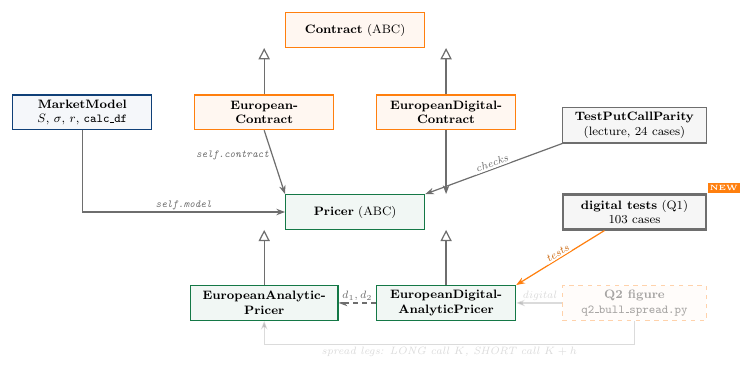